This notebook contains all code nescessary to replicate the figures in the paper "Mpemba in Molecular Motors" by Karthik Cheruvary and Arnab Pal. To run this, you will need to have Julia installed.

For macOS or Linux this can be done by running the following command in the terminal:

```curl -fsSL https://install.julialang.org | sh```

For Windows, run this command in the terminal:
```winget install --name Julia --id 9NJNWW8PVKMN -e -s msstore```

Further details can be found at https://julialang.org/downloads/


You will also need some packages to run this notebook. These are present in an environment. Activate this by running 
```julia --project=.```. This should open a Julia REPL in an environment with all the required packages installed. In the REPL, run ```notebook(dir = pwd())``` and select the notebook


In [6]:
Base.active_project()

"/home/karthik/Documents/imsc-2025/github_folder/Project.toml"

# Functions 

In [ ]:
All the nescessary functions to replicate the plots

In [1]:
using Plots, LinearAlgebra, LaTeXStrings, StatsBase
plot_font = "Computer Modern"
default(fontfamily=plot_font,
        linewidth=2, framestyle=:box, label=nothing, grid=false,palette=:devon10,titlefontsize = 18, guidefontsize = 16,tickfontsize = 14,legendfontsize = 12,foreground_color_legend = nothing, background_color_legend = nothing)

In [2]:
#barriers and energy for forward cycle i.e for 2->5->6->1 in that order
bs = [0.5,1.0,0.3,0.3]  #bs[i] denotes energy barrier between state i,i + 1 of the forward cycle. for i = 4, this is barrier between 4 & 1
es = [0.0,-1.0,-0.5,-0.1]

function rate_ij(bs,es,i,j,t)         # thermal transition rate between i and j
    if (i == 1 && j == 4) || (i == 4 && j == 1)
        return exp(-(bs[4] - es[i])/t)
    else return exp(-(bs[minimum([i,j])] - es[i])/t)
    end
end

# Indices of different loops 
const forward_loop_indices = [[1,2],[5,6],[6,1]]
const backward_loop_indices = [[4,5],[2,3],[3,4]]
const forward_loop_full = [[1,2],[2,5],[5,6],[6,1]]
const backward_loop_full = [[2,3],[3,4],[4,5],[5,2]]
#backward_loop_full = [[1,2],[2,5],[5,6],[6,1]]

#Adding force terms to a rate matrix
function add_force_factors(rates,F,θ)
    rates_mod = copy(rates)
    rates_mod[2,5] = rates[2,5]*exp(-θ*F)
    rates_mod[5,2] = rates[5,2]*exp((1.0 - θ)*F)
    return rates_mod
end

#Constructing the matrix for the master equation, see eq (5) in the paper
function master_eqn(bs,es,t,concs,F = 0.0, θ = 0.0,conc_eq = true)
    # first construct bare rate constants at t
    matrix = zeros(6,6)
    #adding thermal transition rates for the forward loop
    matrix[2,5] = rate_ij(bs,es,1,2,t)
    matrix[5,2] = rate_ij(bs,es,2,1,t)
    matrix[5,6] = rate_ij(bs,es,2,3,t)
    matrix[6,5] = rate_ij(bs,es,3,2,t)
    matrix[6,1] = rate_ij(bs,es,3,4,t)
    matrix[1,6] = rate_ij(bs,es,4,3,t)
    matrix[1,2] = rate_ij(bs,es,4,1,t)
    matrix[2,1] = rate_ij(bs,es,1,4,t)
    # backward rate constants are symmetrical with resepct to forward rates except for 5 -> 4, to satisfy equilibrium condition
    for i = eachindex(forward_loop_indices)
        f = forward_loop_indices[i]
        b = backward_loop_indices[i]
        matrix[b[1],b[2]] = matrix[f[1],f[2]]
        matrix[b[2],b[1]] = matrix[f[2],f[1]]
    end
    matrix[5,4] = matrix[2,1]*(matrix[5,2]/matrix[2,5])^2 #follows from eq (3) in the paper
    # without force or external concentration maintenance, rates are in eq and satisfy balance conditions
    K_eq = prod([matrix[i[1],i[2]]/matrix[i[2],i[1]] for i in forward_loop_full])
    atp = concs[1]
    adp = concs[2]
    if conc_eq
        p = K_eq*atp/adp #If there is chemical equilibrium, the p concentration can be obtained from the eq constant
    else
        p = concs[3]*K_eq*atp/adp#If not, it has to be specified
    
    end
    # adding force factors since rate constants are no longer required
    matrix = add_force_factors(matrix,F,θ)
    # adding concentration factors to get rates
    add_concs = copy(matrix)
    add_concs[1,2] *= atp
    add_concs[4,5] *= atp
    add_concs[6,5] *= adp
    add_concs[3,2] *= adp
    add_concs[1,6]*= p
    add_concs[4,3]*= p
    # fixing diagonal
    for i = 1:6
        add_concs[i,i] = -sum([add_concs[i,j] for j = 1:6])
    end
    # transpose so that right evects are needed
    add_concs = add_concs'
    return add_concs
end


#calculating the steady state distribution
function ss(bs,es,t,concs,F = 0.0, θ = 0.0,concs_eq = true)
    M = master_eqn(bs,es,t,concs,F,θ,concs_eq)
    eq = nullspace(M)[:,1]
    return eq./sum(eq)
end

#For a given distribution and rate matrix, return a matrix with ijth entry being the current bw i and j
function currents(M,p)
    M_copy = M'  #taking transpose since usually M comes out of the master_eqn matrix
    currents = zeros(size(M_copy))
    for i in range(1,size(M_copy)[1]),j in range(1,size(M_copy)[2])
        currents[i,j] = M_copy[i,j]*p[i] - M_copy[j,i]*p[j]
    end
    for i = 1:size(M_copy)[1] M_copy[i,i] = 0.0 end
    return (M_copy,ss_vec)
end
    
    
function entropy_production(M) #steady state entropy production rate
    ss_vec = nullspace(M)[:,1]
    ss_vec = abs.(ss_vec./sum(ss_vec))
    M_copy = M'
    entropy_prod = zeros(size(M_copy))
    for i in range(1,size(M_copy)[1]),j in range(1,size(M_copy)[2])    
        if M_copy[i,j] ==0 || M_copy[j,i] ==0 || ss_vec[i] ==0 || ss_vec[j] == 0
            entropy_prod[i,j] = 0
        else w_ij =  M_copy[i,j]*ss_vec[i]
             w_ji =  M_copy[j,i]*ss_vec[j]
            entropy_prod[i,j] = (w_ij - w_ji)*log(w_ij/w_ji)
        end
    end
    for i = 1:size(entropy_prod)[1] entropy_prod[i,i] = 0.0 end
    
    return sum(0.5 .*entropy_prod)
end

#Gives the effective barriers accounting for force and concentration terms. By default, true_barriers = false, meaning it only gives the thermal barriers
function effective_barrier(bs,es,t,concs,F = 0.0, θ = 0.0,conc_eq = true;true_barriers = false) 
    # first construct bare rate constants at t
    matrix = zeros(6,6)
    matrix[2,5] = rate_ij(bs,es,1,2,t)
    matrix[5,2] = rate_ij(bs,es,2,1,t)
    matrix[5,6] = rate_ij(bs,es,2,3,t)
    matrix[6,5] = rate_ij(bs,es,3,2,t)
    matrix[6,1] = rate_ij(bs,es,3,4,t)
    matrix[1,6] = rate_ij(bs,es,4,3,t)
    matrix[1,2] = rate_ij(bs,es,4,1,t)
    matrix[2,1] = rate_ij(bs,es,1,4,t)
    # backward rate constants are symmetrical to forward rates except for 5 -> 4, to satisfy equilibrium condition
    for i = eachindex(forward_loop_indices)
        f = forward_loop_indices[i]
        b = backward_loop_indices[i]
        matrix[b[1],b[2]] = matrix[f[1],f[2]]
        matrix[b[2],b[1]] = matrix[f[2],f[1]]
    end
    matrix[5,4] = matrix[2,1]*(matrix[5,2]/matrix[2,5])^2
    # without force or external concentration maintenance, rates are in eq and satisfy balance conditions
    K_eq = prod([matrix[i[1],i[2]]/matrix[i[2],i[1]] for i in forward_loop_full])
    atp = concs[1]
    adp = concs[2]
    if conc_eq == false
        p = concs[3]
    else 
        p = K_eq*atp/adp
        
    end
     # adding force factors since rate constants are no longer required
    if !true_barriers matrix = add_force_factors(matrix,F,θ) end
    # adding concentration factors to get rates
    if !true_barriers
        matrix[1,2] *= atp
        matrix[4,5] *= atp
        matrix[6,5] *= adp
        matrix[3,2] *= adp
        matrix[1,6]*= p
        matrix[4,3]*= p
    end
    es_forward = zeros(5)
    b12 = -t * log(matrix[1,2]) + es_forward[1]
    es_forward[2] = b12 + t*log(matrix[2,1])
    b25 = -t * log(matrix[2,5]) + es_forward[2]
    es_forward[3] = b25 + t*log(matrix[5,2])
    b56 = -t * log(matrix[5,6]) + es_forward[3]
    es_forward[4] = b56 + t*log(matrix[6,5])
    b61 = -t * log(matrix[6,1]) + es_forward[4]
    es_forward[5] = b61 + t*log(matrix[1,6])
  
    b_forward = [b12,b25,b56,b61]

    es_backward = zeros(5)
    es_backward[1] = es_forward[2]
    b23 = -t * log(matrix[2,3]) + es_backward[1]
    es_backward[2] = b23 + t*log(matrix[3,2])
    b34 = -t * log(matrix[3,4]) + es_backward[2]
    es_backward[3] = b34 + t*log(matrix[4,3])
    b45 = -t * log(matrix[4,5]) + es_backward[3]
    es_backward[4] = b45 + t*log(matrix[5,4])
    b52 = -t * log(matrix[5,2]) + es_backward[4]
    es_backward[5] = b52 + t*log(matrix[2,5])
    b_backward = [b23,b34,b45,b52]

    c_ff = [atp,1.0,1.0,1.0] #order 1->2, 2->5, 5->6, 6->1
    c_fb = [p,1.0,1.0,adp]  #order 2 ->1, 5->2, 6 ->5, 1->6
    c_bf = [1.0,1.0,atp,1.0] #order 2->3, 3->4, 4->5, 5->2
    c_bb = [adp,p,1.0,1.0] #order 3->2, 4->3, 5->4, 2->5
    
    return (es_forward = es_forward, es_backward = es_backward, b_forward = b_forward, b_backward = b_backward,c_forawrd = (c_ff,c_fb), c_backward = (c_bf,c_bb))
end

effective_barrier (generic function with 4 methods)

# plots

Plot showing v as a function of F for different c. Note that for c < 1, the walker prefers to move in the negative i.e 25 direction since v < 0 for F = 0. Thus in this case, a physical load corresponds to negative F. Fig. 2 in the paper

(0.803030303030303, 2.2615125193130303e-5)
(0.803030303030303, 1.9298946898751307e-5)
(-0.398989898989899, 1.5609248728946923e-5)
(-0.398989898989899, 1.75323798584405e-5)


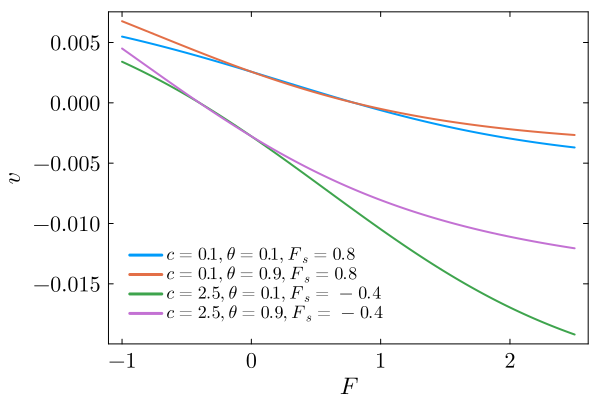

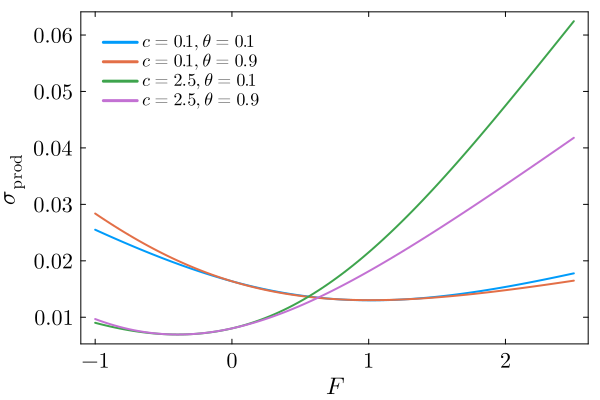

"/home/karthik/Documents/imsc-2025/notes/images/S_prod_vs_f.pdf"

In [81]:
F_list = range(-1.0,2.5,length  = 100)

aff_list = []

T_b = 1.0
s = 0.5
c = 0.1

colors = palette(:devon10)
plot_v = plot(xlabel = L"F",ylabel = L"v",palette = :default)
plot_S_prod = plot(xlabel = L"F",ylabel = L"\sigma_\mathrm{prod}",palette = :default)
J25(M,vec) =  vec[2]*M[5,2] - vec[5]*M[2,5] 
for c in [0.1,2.5],  θ in [0.1,0.9]
    concs_test = s.* [0.1,1.0,c/s] 
    v_list = []
    S_prod_list = []
    #println(affinity(bs,es,T_b,concs_test,0.0,θ,false))
    for F in F_list
        M_relax = master_eqn(bs,es,T_b,concs_test,F,θ,false)
        #println(typeof(M_relax))
        ss_F = ss(bs,es,T_b,concs_test,F,θ,false)
        #println(M_relax*ss_test(F))
        current = J25(M_relax,ss_F)
        push!(v_list,current)
        push!(aff_list,affinity(bs,es,T_b,concs_test,F,θ,false))
        push!(S_prod_list,entropy_production(M_relax))
        #println(current(100,0.0))
        
        
    end
    F_stall = collect(F_list)[argmin(abs.(v_list))]
    println((F_stall,minimum(abs.(v_list))))
    plot!(plot_v,F_list,v_list,label = L"c = %$(c), \theta = %$(θ),F_s = %$(round(F_stall,digits = 2))",legend = :bottomleft)
    plot!(plot_S_prod,F_list,S_prod_list,label = L"c = %$(c), \theta = %$(θ)")
end
display(plot_v)
display(plot_S_prod)
savefig(plot_v,"/home/karthik/Documents/imsc-2025/notes/images/v_vs_f.pdf")
savefig(plot_S_prod,"/home/karthik/Documents/imsc-2025/notes/images/S_prod_vs_f.pdf")

Plots showing decreasing $|a_2|$ and crossover in $L_1$ and KLD norms. Fig. 3 in the paper

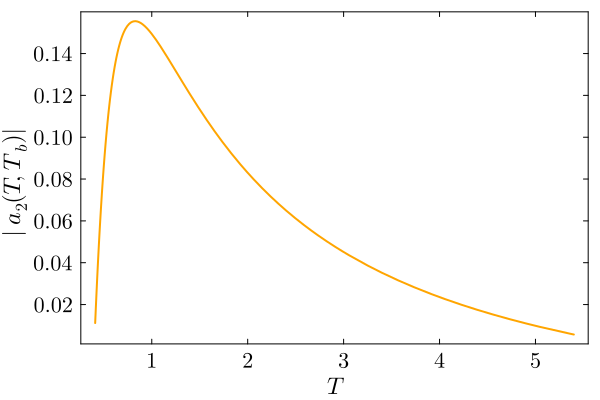

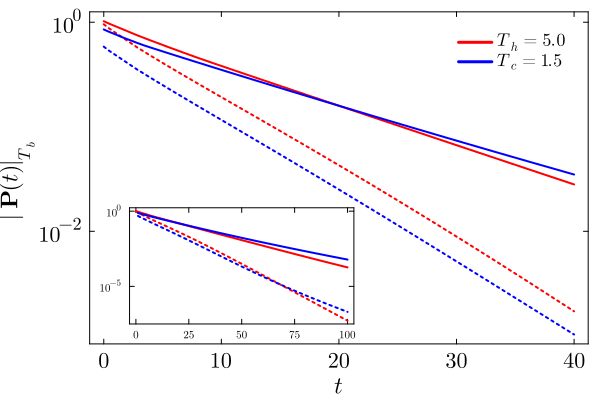

In [3]:
concs_test = 2.5 .*[0.1,1.0] 
T_b = 0.4
M_relax = master_eqn(bs,es,T_b,concs_test)
    
L_evec_dom = eigvecs(M_relax')[:,5]
R_evec_dom = eigvecs(M_relax)[:,5]
ss_test(T) = ss(bs,es,T,concs_test)



T_h = 5.0
T_c = 1.5

coeff(t) = dot(L_evec_dom,ss(bs,es,t,concs_test))/dot(L_evec_dom,R_evec_dom)
display(plot(t ->abs(coeff(t)),T_b + 0.01,T_b + 5.0,xlabel = L"T",ylabel = L"|a_2(T,T_b)|",lc = :orange))

hot_relax_l1(t) = norm(ss_test(T_b) - exp(M_relax .* t)*ss_test(T_h),1)
cold_relax_l1(t) = norm(ss_test(T_b) - exp(M_relax .* t)*ss_test(T_c),1)

hot_relax_kl(t) = kldivergence(exp(M_relax .* t)*ss_test(T_h),ss_test(T_b))
cold_relax_kl(t) = kldivergence(exp(M_relax .* t)*ss_test(T_c),ss_test(T_b))

plot(hot_relax_kl,0.0,40.0,yscale = :log10,lc = :red,xlabel = L"t",ylabel = L"|\mathbf{P}(t)|_{T_b}",ls = :dot)
plot!(cold_relax_kl,0.0,40.0,yscale = :log10,lc = :blue,legend = :bottomleft,ls = :dot)
plot!(hot_relax_l1,0.0,40.0,yscale = :log10,lc = :red,label = L"T_h = %$(T_h)",)
plot!(cold_relax_l1,0.0,40.0,yscale = :log10,lc = :blue,label = L"T_c = %$(T_c)",legend = :topright)
plot!(
   hot_relax_kl,0.0,100.0,yscale = :log10,lc = :red,ls = :dot,ytickfontsize = 7,xtickfontsize = 7;
    inset = (1, bbox(0.08, 0.06, 0.45, 0.35, :bottom, :left)),
    subplot = 2,
    bg_inside = nothing
)
plot!(
   cold_relax_kl,1.0,100.0,yscale = :log10,lc = :blue,ls = :dot;subplot = 2,
    
)
plot!(
   hot_relax_l1,0.0,100.0,yscale = :log10,lc = :red;subplot = 2,
    
)
plot!(
   cold_relax_l1,1.0,100.0,yscale = :log10,lc = :blue;subplot = 2,
    
)


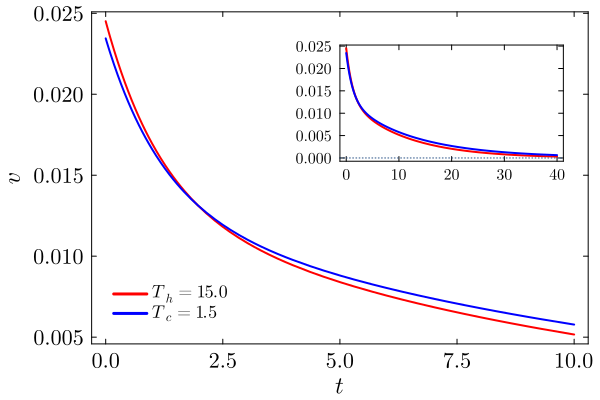

In [142]:

colors = palette(:devon10)
concs_test = 2.5 .*[0.1,1.0] 
T_b = 0.4
M_relax = master_eqn(bs,es,T_b,concs_test)
    
L_evec_dom = eigvecs(M_relax')[:,5]
R_evec_dom = eigvecs(M_relax)[:,5]
ss_test(T) = ss(bs,es,T,concs_test)



T_h = 15.0
T_c = 1.5
J25(M,vec) =  vec[2]*M[5,2] - vec[5]*M[2,5] 
p(t,T_b) = exp(M_relax.*t)*ss_test(T_b)
plot(t -> J25(M_relax,p(t,T_h)),0.0,10.0,lc = :red,xlabel = L"t",ylabel = L"v",label = L"T_h = %$(T_h)")
plot!(t -> J25(M_relax,p(t,T_c)),0.0,10.0,lc = :blue,label = L"T_c = %$(T_c)",legend = :bottomleft)
plot!(
   t -> J25(M_relax,p(t,T_h)),0.0,40.0,lc = :red,ytickfontsize = 10,xtickfontsize = 10;
    inset = (1, bbox(0.05, 0.1, 0.45, 0.35, :top, :right)),
    subplot = 2,
    bg_inside = nothing
)
# plot(;subplot = 2)
plot!(t -> J25(M_relax,p(t,T_c)),0.0,40.0,lc = :blue;subplot = 2)
hline!([0.0],subplot = 2,ls = :dot,lw = 1.0)
#savefig("/home/karthik/Documents/imsc-2025/notes/images/relaxation_current_eq_alt.pdf")

In [ ]:
master_eqn(0.4,)

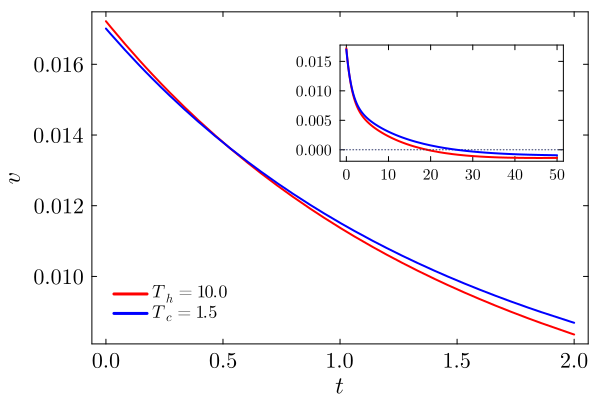

In [140]:

colors = palette(:devon10)
c = 1.0
s = 1.5
concs_test = s.* [0.1,1.0,c/s] 
T_b = 0.4
M_relax = master_eqn(bs,es,T_b,concs_test,0.4,0.1,false)
    

ss_test(T) = ss(bs,es,T,concs_test,0.4,0.1,false)



T_h = 10.0
T_c = 1.5
J25(M,vec) =  vec[2]*M[5,2] - vec[5]*M[2,5] 
p(t,T_b) = exp(M_relax.*t)*ss_test(T_b)
plot(t -> abs(J25(M_relax,p(t,T_h))),0.0,2.0,lc = :red,xlabel = L"t",ylabel = L"v",label = L"T_h = %$(T_h)")
plot!(t -> abs(J25(M_relax,p(t,T_c))),0.0,2.0,lc = :blue,label = L"T_c = %$(T_c)",legend = :bottomleft)
plot!(
   t -> J25(M_relax,p(t,T_h)),0.0,50.0,lc = :red,ytickfontsize = 10,xtickfontsize = 10;
    inset = (1, bbox(0.05, 0.1, 0.45, 0.35, :top, :right)),
    subplot = 2,
    bg_inside = nothing
)
hline!([0.0],subplot = 2,ls = :dot,lw = 1.0)
# plot(;subplot = 2)
plot!(t -> J25(M_relax,p(t,T_c)),0.0,50.0,lc = :blue;subplot = 2)
#savefig("/home/karthik/Documents/imsc-2025/notes/images/relaxation_current_non_eq.pdf")

Energy landscape for the forward cycle. coloured directed transitions involve binding of chemical species. Effects of force, concentration terms not included, Fig. 4 in the paper

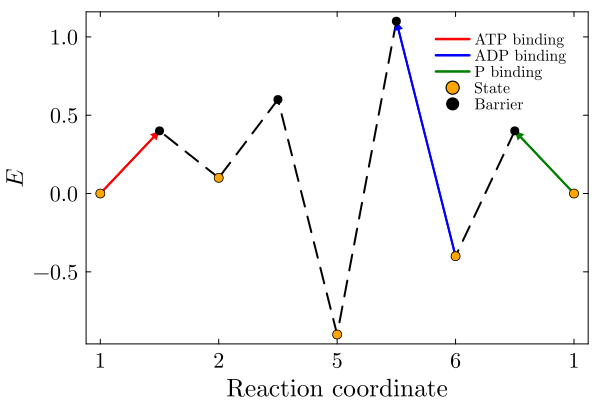

In [4]:
test = effective_barrier(bs,es,T_b,concs_test;true_barriers = true)
labels = ["1","2", "5", "6", "1"]
landscape = []
landscape_indices = [0.5 + 0.5*i for i = 1:9]
for i = eachindex(test.es_forward)
    push!(landscape,test.es_forward[i])
    if i <= length(test.b_forward)
        push!(landscape,test.b_forward[i])
    end
end
index = [1,2,3,4,5]
colors = [:red,:black,:black,:black,:black,:blue,:black,:green]
labels_list = ["ATP binding", :none,:none,:none,:none,"ADP binding",:none,"P binding"]
arrows = [(:closed,:end),:none,:none,:none,:none,(:closed,:start),:none,(:closed,:end)]
arrow_end = [2,0,0,0,0,1,0,1]
plot_f = plot(ylabel = L"E",xlabel = "Reaction coordinate",legendfontsize = 10)
for i in range(1,length(landscape_indices) - 1)
    if arrow_end[i] == 2
        plot!(plot_f,[landscape_indices[i],landscape_indices[i + 1]],[landscape[i],landscape[i + 1]],arrow = :closed,color = colors[i],label = labels_list[i])
    elseif arrow_end[i] == 1
        plot!(plot_f,[landscape_indices[i + 1],landscape_indices[i]],[landscape[i + 1],landscape[i]],arrow = :closed,color = colors[i],label = labels_list[i])
    elseif arrow_end[i] == 0
        plot!(plot_f,[landscape_indices[i + 1],landscape_indices[i]],[landscape[i + 1],landscape[i]],arrow = :none,color = colors[i],ls = :dash,label = labels_list[i])
    end
end

scatter!(plot_f,index,test.es_forward,color = :orange,label = "State",markersize = 5)
scatter!(plot_f,index[1:4] .+ 0.5, test.b_forward,label = "Barrier",color = :black,markersize = 5)
xticks!(plot_f,[1,2,3,4,5],labels)


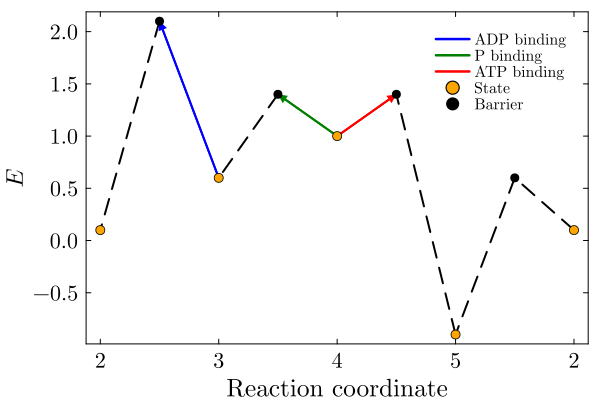

In [5]:
test = effective_barrier(bs,es,T_b,concs_test;true_barriers = true)
labels = ["2","3", "4", "5", "2"]
landscape = []
landscape_indices = [0.5 + 0.5*i for i = 1:9]
for i = eachindex(test.es_backward)
    push!(landscape,test.es_backward[i])
    if i <= length(test.b_backward)
        push!(landscape,test.b_backward[i])
    end
end
index = [1,2,3,4,5]
colors = [:black,:blue,:black,:green,:red,:black,:black,:black]
labels_list = [:none,"ADP binding",:none,"P binding","ATP binding",:none,:none,:none]
arrows = [(:closed,:end),:none,:none,:none,:none,(:closed,:start),:none,(:closed,:end)]
arrow_end = [0,1,0,1,2,0,0,0]
plot_f = plot(ylabel = L"E",xlabel = "Reaction coordinate",legendfontsize = 10)
for i in range(1,length(landscape_indices) - 1)
    if arrow_end[i] == 2
        plot!(plot_f,[landscape_indices[i],landscape_indices[i + 1]],[landscape[i],landscape[i + 1]],arrow = :closed,color = colors[i],label = labels_list[i])
    elseif arrow_end[i] == 1
        plot!(plot_f,[landscape_indices[i + 1],landscape_indices[i]],[landscape[i + 1],landscape[i]],arrow = :closed,color = colors[i],label = labels_list[i])
    elseif arrow_end[i] == 0
        plot!(plot_f,[landscape_indices[i + 1],landscape_indices[i]],[landscape[i + 1],landscape[i]],arrow = :none,color = colors[i],ls = :dash,label = labels_list[i])
    end
end

scatter!(plot_f,index,test.es_backward,color = :orange,label = "State",markersize = 5)
scatter!(plot_f,index[1:4] .+ 0.5, test.b_backward,label = "Barrier",color = :black,ylabel = L"E",xlabel = "Reaction coordinate",markersize = 5)
xticks!(plot_f,[1,2,3,4,5],labels)


Phase diagram of Mpemba effect as a function of t and s. Takes a little while to run because of the resolution. Fig. 5(a) in the paper

In [10]:
t_b_range = range(0.1,10.0,length = 200)
scale_range = range(0.1,20.0,length = 200)
checklist = []
function nzero(x)
    if x ==0 return false
    else return true
    end
end


for t_b in t_b_range,s in scale_range
    concs_test = s .*[0.1,1.0] 
    M_relax = master_eqn(bs,es,t_b,concs_test)
    L_evec_dom = eigvecs(M_relax')[:,5]
    R_evec_dom = eigvecs(M_relax)[:,5]
  
    coeff(t) = abs(dot(L_evec_dom,ss(bs,es,t,concs_test))/dot(L_evec_dom,R_evec_dom))
    t_list = range(t_b + 0.1,t_b + 10.0,length = 50)
    a_2_list = coeff.(t_list)
    
    if !issorted(a_2_list) push!(checklist,1) 
    else push!(checklist,0)
    end 
    
    
end
    

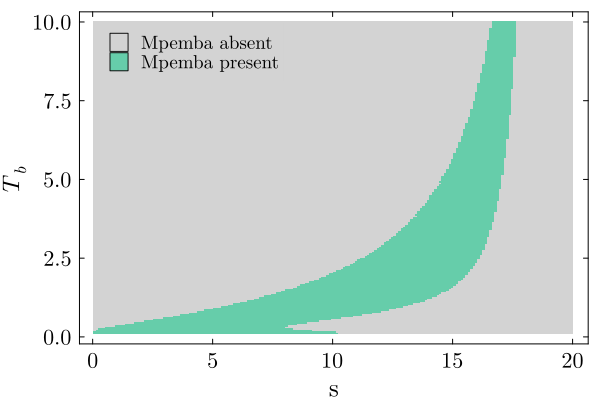

In [11]:
z_list = reshape(checklist, (length(scale_range), length(t_b_range)))'
heatmap(scale_range, t_b_range, z_list,
    xlabel="s", 
    ylabel=L"T_b",
    c = c=cgrad([ colorant"#d3d3d3ff", colorant"#66cdaaff"]),
    colorbar = :false,
    colorbar_ticks = [0.0,1.0],
    foreground_color_legend = nothing,
    background_color_legend = colorant"#d3d3d3ff")
scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#d3d3d3ff",
    label="Mpemba absent"
)

display(scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#66cdaaff",
    label="Mpemba present"
))


Showing variation in $a_2(T)$ as $s$ is changed. Fig. 5(b) in the paper

In [12]:
a_2_s_normalized = []
T_b = 7.0
c_list = [14.0,16.0,16.5,17.0,17.5,18.0,19.0]
concs_list = [c .*[0.1,1.0] for c in c_list] 

for concs in concs_list
    M_relax = master_eqn(bs,es,T_b,concs)
    L_evec_dom = eigvecs(M_relax')[:,5]
    R_evec_dom = eigvecs(M_relax)[:,5]

    println(eigvals(M_relax))
    coeff(t) = dot(L_evec_dom,ss(bs,es,t,concs))/dot(L_evec_dom,R_evec_dom)
    t_list = range(T_b + 0.1,T_b + 50.0,length = 100)
    a_2_list = abs.(coeff.(t_list))
    push!(a_2_s_normalized,a_2_list./maximum(a_2_list))
end 


[-13.094215648341278, -12.938958563408834, -3.022672518598393, -2.2253840417084216, -0.8545845364531044, -2.220446049250313e-16]
[-14.688988576595627, -14.553685521531255, -3.16356921531581, -2.411677943503345, -0.9241486943834831, 2.220446049250313e-16]
[-15.088435045775249, -14.957349675710837, -3.1992051007202456, -2.458278280055004, -0.9403655097730439, 2.220446049250313e-16]
[-15.488128931331383, -15.361007970486588, -3.2350371863238276, -2.504888172524174, -0.9561350120733076, -8.881784197001252e-16]
[-15.888048710354674, -15.764660881862417, -3.271075875291569, -2.551507140934739, -0.9714683250007563, 3.3306690738754696e-16]
[-16.28817526888981, -16.168308835633365, -3.3073292093043163, -2.5981347565055026, -0.9863765238160095, 1.7763568394002505e-15]
[-17.088982411216463, -16.975591360232983, -3.380502150420155, -2.691414430353758, -1.0149615633354354, -2.6645352591003757e-15]


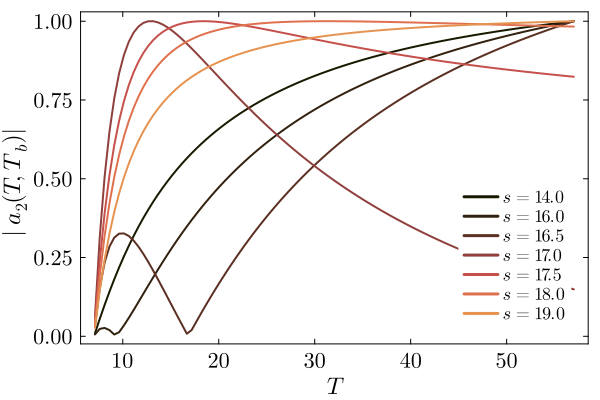

In [13]:
plot_a2 = plot(xlabel = L"T",ylabel = L"|a_2(T,T_b)|",background_color_legend = :white,palette = :lajolla10)
t_list = range(T_b+ 0.1,T_b + 50.0,length = 100)
    
for i = eachindex(a_2_s_normalized)
    plot!(plot_a2,t_list,a_2_s_normalized[i],label = L"s = %$(round(c_list[i],digits = 2))")
end
plot_a2


Showing variation in $a_2(T)$ as $T_b$ is changed. Fig. 5(c) in the paper

In [15]:
T_b_list = [1.0,2.0,2.5,3.0,3.5,4.0,5.0,8.0]
a_2_s_normalized = []

concs =  15.0 .* [0.1,1.0] 

for T_b in T_b_list
    M_relax = master_eqn(bs,es,T_b,concs)
    L_evec_dom = eigvecs(M_relax')[:,5]
    R_evec_dom = eigvecs(M_relax)[:,5]

    println(eigvals(M_relax))
    coeff(t) = dot(L_evec_dom,ss(bs,es,t,concs))/dot(L_evec_dom,R_evec_dom)
    t_list = range(T_b + 0.01,T_b + 20.0,length = 200)
    a_2_list = abs.(coeff.(t_list))
    push!(a_2_s_normalized,a_2_list./maximum(a_2_list))
end 


[-4.027048095414533, -3.926217846556571, -2.036761112671544, -1.1763026409142112, -0.5126656351833341, 2.220446049250313e-16]
[-8.22844970627342, -8.11546066213164, -2.5347774496159183, -1.6904790546342026, -0.7266791754554973, 5.551115123125783e-16]
[-9.519147332581781, -9.399883932127642, -2.6603040947357766, -1.843299666930771, -0.7725120504921995, -7.771561172376096e-16]
[-10.494498877144707, -10.370147617483028, -2.753532782743283, -1.9562473796578181, -0.8031474930822025, 2.220446049250313e-16]
[-11.253935846934244, -11.12541317491537, -2.826453257061611, -2.0420431827046333, -0.8250147882008385, -5.551115123125783e-16]
[-11.860574847782562, -11.728580861368442, -2.8854860892295777, -2.108882491961399, -0.841391173194583, 7.771561172376096e-16]
[-12.767037002855536, -12.629610718760311, -2.975836088160485, -2.205398021203954, -0.8642685857210499, -1.1102230246251565e-16]
[-14.26267670753345, -14.115588706717709, -3.132994775088803, -2.3541453723488854, -0.8984517098258742, 0.0]


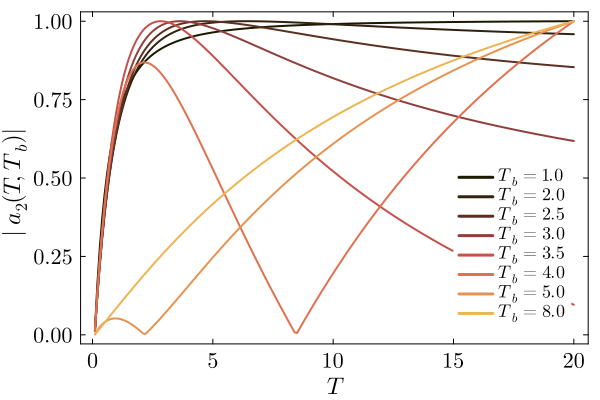

In [16]:
plot_a2 = plot(xlabel = L"T",ylabel = L"|a_2(T,T_b)|",background_color_legend = :white,palette = :lajolla10)

    
for i = eachindex(a_2_s_normalized)
    t_list = range(0.1, 20.0,length = 200)
    plot!(plot_a2,t_list,a_2_s_normalized[i],label = L"T_b = %$(round(T_b_list[i],digits = 2))")
end
plot_a2


Plot showing variation in steady state occupation probability with $T_b$ for small s. Fig. 5(d) in the paper

[0.002429350251644119, 4.4685400649226716e-5, 6.021757224795921e-7, 1.102923308015763e-7, 0.9842614489274211, 0.013263802952232229]
[0.15918990519676218, 0.0048276779109292, 0.0007925598693500411, 0.001072613144004765, 0.716490929890721, 0.11762631398823271]
[0.40507515045533055, 0.014512451421831747, 0.005482096021899217, 0.014450648222482258, 0.40680759455682153, 0.1536720593216347]
[0.5928225231303983, 0.02509067159667125, 0.021808721852305552, 0.11196971143193821, 0.13284231112818679, 0.11546606086049982]
[0.5150117048828402, 0.02455310461546932, 0.03870196018874478, 0.31989702660325675, 0.03952877087495557, 0.06230743283473332]
[0.46999399066034403, 0.023043409164758964, 0.041782924737766694, 0.3863105104962383, 0.028035125986740846, 0.05083403895415113]


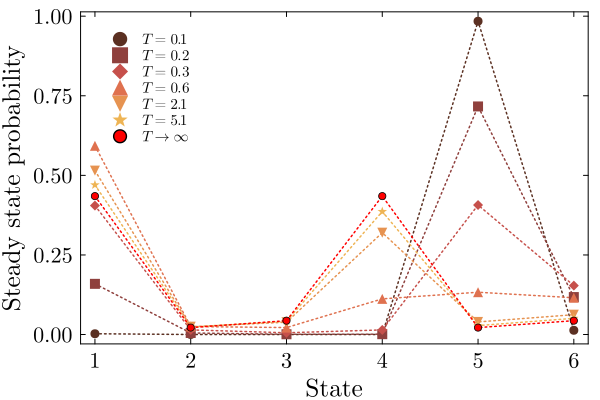

In [17]:

t_list = [0.1,0.2,0.3,0.6,2.1,5.1] 
markers = [:circle, :square, :diamond, :utriangle, :dtriangle,
           :star5, :hexagon, :cross, :xcross, :pentagon]

concs_test = 0.5 .* [0.1,1.0]
F = 0.0
θ = 0.0
ss_test(T) = ss(bs,es,T,concs_test,F,θ)
ss_high_temp = nullspace(master_eqn(zeros(4),zeros(4),0.1,concs_test,F,θ))
ss_high_temp = ss_high_temp ./ sum(ss_high_temp)
ss_list = [ss_test(t) for t in t_list]
colors = palette(:lajolla10)[3:end]
plot_ss = plot(legendfontsize = 10)
test_high_temp = master_eqn(zeros(4),zeros(4),1.0,10.0concs_test)'
for i = eachindex(t_list)
        plot!(plot_ss,(ss_list[i]),color = colors[i],ls = :dot,lw = 1.5)
        
end
for i = eachindex(t_list)
        scatter!(plot_ss,(ss_list[i]),label = L"T = %$(round(t_list[i],digits = 2))",color = colors[i], marker = markers[i],markerstrokewidth = 0,markersize = 5)
        println(ss_list[i] )
end
plot!(plot_ss, ss_high_temp, lc = :red,ls = :dot,lw = 1.5 )

scatter!(plot_ss, ss_high_temp,label = L"T \to\infty",color = :red,xlabel = "State", ylabel = "Steady state probability",background_color_legend = nothing,foreground_color_legend = nothing)
plot_ss


Energy lanscape for large $s$ in a situation where Mpemba is present. Fig. 6 (a) in the paper

[7.048457766962464e-5, 4.537719732753538e-5, 1.747138002646139e-8, 3.199994874635486e-9, 0.9994992847989648, 0.0003848327546630783]
[0.006236667925876233, 0.00661977804510808, 3.1050541241324175e-5, 4.202233793545007e-5, 0.9824621722323688, 0.004608308917470112]
[0.026432514260083414, 0.03314451714794137, 0.00035772518040433934, 0.000942953337865357, 0.9290946720012822, 0.010027618072423453]
[0.09306883060121397, 0.13786686245651888, 0.003423810939205429, 0.01757843148519104, 0.7299347315655571, 0.018127332952313443]
[0.13949362347703165, 0.2229005231489502, 0.008084747419627432, 0.05620063081392499, 0.5532536058522125, 0.02006686928825324]
[0.16201533123520168, 0.2703419686959283, 0.01217508425533251, 0.10063503845620858, 0.43523154834492844, 0.01960102901240041]
[0.17173936102827042, 0.294708263420125, 0.015267796905816472, 0.14116078407282218, 0.3585486520350664, 0.018575142537899495]


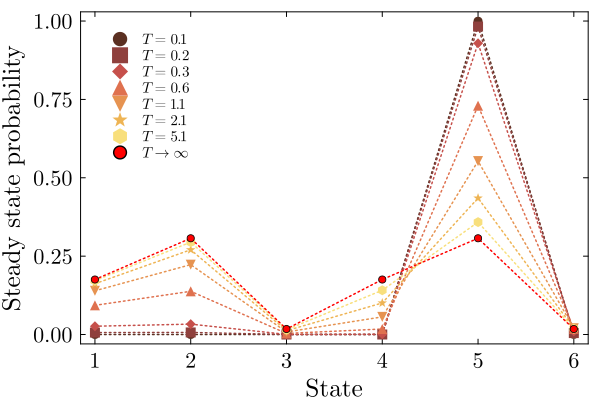

In [18]:

t_list = [0.1,0.2,0.3,0.6,1.1,2.1,5.1] 
pushfirst!(t_list)
concs_test = 17.5 .* [0.1,1.0]#[1.0,4.0,10.0]
F = 0.0
θ = 0.0
ss_test(T) = ss(bs,es,T,concs_test,F,θ)
ss_high_temp = nullspace(master_eqn(zeros(4),zeros(4),0.1,concs_test,F,θ))
ss_high_temp = ss_high_temp ./ sum(ss_high_temp)
ss_list = [ss_test(t) for t in t_list]

plot_ss = plot(legendfontsize = 10)
test_high_temp = master_eqn(zeros(4),zeros(4),1.0,10.0concs_test)'
for i = eachindex(t_list)
        plot!(plot_ss,(ss_list[i]),color = colors[i],ls = :dot,lw = 1.5)
        
end
for i = eachindex(t_list)
        scatter!(plot_ss,(ss_list[i]),label = L"T = %$(round(t_list[i],digits = 2))",color = colors[i], marker = markers[i],markerstrokewidth = 0,markersize = 5)
        println(ss_list[i] )
end
plot!(plot_ss, ss_high_temp, lc = :red,ls = :dot,lw = 1.5 )

scatter!(plot_ss, ss_high_temp,label = L"T \to\infty",color = :red,xlabel = "State", ylabel = "Steady state probability",background_color_legend = nothing,foreground_color_legend = nothing)
 plot_ss


$a_2$ plot for the same parameters. Fig. 6(b) in the paper

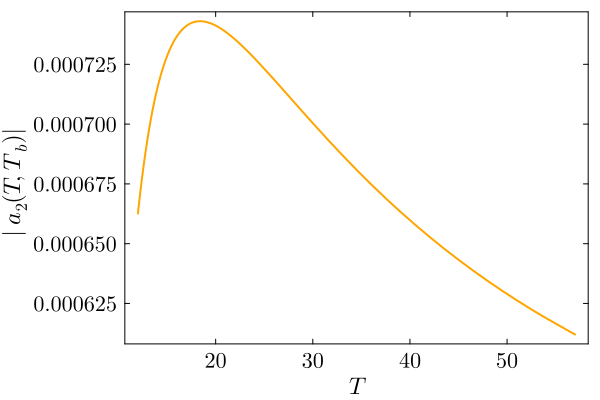

In [19]:
concs_test = 17.5 .*[0.1,1.0] 
T_b = 7.0
M_relax = master_eqn(bs,es,T_b,concs_test)
    
L_evec_dom = eigvecs(M_relax')[:,5]
R_evec_dom = eigvecs(M_relax)[:,5] 
ss_test(T) = ss(bs,es,T,concs_test)


coeff(t) = dot(L_evec_dom,ss(bs,es,t,concs_test))/dot(L_evec_dom,R_evec_dom)
plot(t ->abs(coeff(t)),T_b + 5,T_b + 50.0,xlabel = L"T",ylabel = L"|a_2(T,T_b)|",lc = :orange)


Phase diagra of Mpemba for different values of force

In [20]:
t_b_range = range(0.1,10.0,length = 200)
scale_range = range(0.1,20.0,length = 200)
diff_Fs = []

F_list = [-1.66,1.66]
θ = 0.6
entropy_prod_list = []
for F in F_list
    checklist = []
    S = []
    for t_b in t_b_range,r in scale_range
        concs_test = r .*[0.1,1.0] 
        M_relax = master_eqn(bs,es,t_b,concs_test,F,θ)
        e_prod =entropy_production(M_relax) 
       
        L_evec_dom = eigvecs(M_relax')[:,5]
        R_evec_dom = eigvecs(M_relax)[:,5]
        λ_max = eigvecs(M_relax)[5]
        if typeof(λ_max) == ComplexF64 && imag(λ_max) > 1e-5
            println(λ_max)
            println(t_b)
            println(r)
        end
        coeff(t) = abs(dot(L_evec_dom,ss(bs,es,t,concs_test,F,θ))/dot(L_evec_dom,R_evec_dom))
        t_list = range(t_b + 0.1,t_b + 10.0,length = 50)
        a_2_list = coeff.(t_list)
        push!(checklist,ifelse(issorted(a_2_list), 0.0, 1.0))
        push!(S,e_prod)
    end
    push!(entropy_prod_list, S)
    push!(diff_Fs,checklist)
end
    

Mpemba phase plot for negative $F$. Fig. 7 (a) in the paper

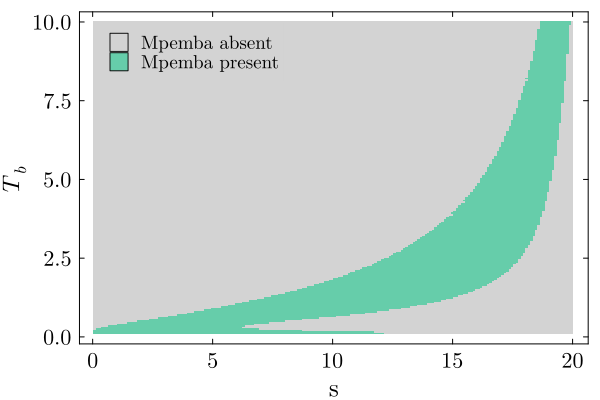

In [21]:
z_list = reshape(diff_Fs[1], (length(scale_range), length(t_b_range)))'
heatmap(scale_range, t_b_range, z_list,
    xlabel="s", 
    ylabel=L"T_b",
    c = c=cgrad([ colorant"#d3d3d3ff", colorant"#66cdaaff"]),
    colorbar = :false,
    colorbar_ticks = [0.0,1.0],
    foreground_color_legend = nothing,
    background_color_legend = colorant"#d3d3d3ff")
scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#d3d3d3ff",
    label="Mpemba absent"
)

display(scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#66cdaaff",
    label="Mpemba present"
))


Mpemba phase plot for positive $F$. Fig. 7(b) in the paper

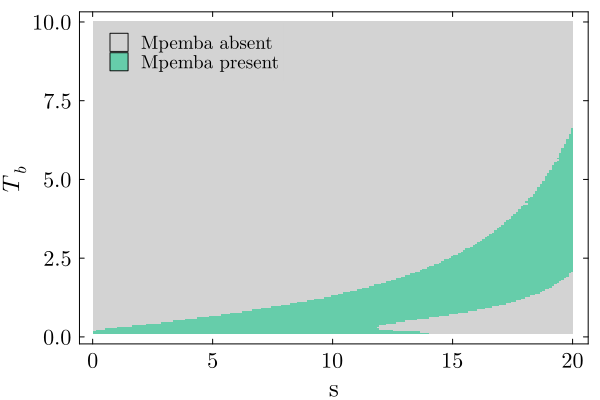

In [22]:
z_list = reshape(diff_Fs[2], (length(scale_range), length(t_b_range)))'
heatmap(scale_range, t_b_range, z_list,
    xlabel="s", 
    ylabel=L"T_b",
    c = c=cgrad([ colorant"#d3d3d3ff", colorant"#66cdaaff"]),
    colorbar = :false,
    colorbar_ticks = [0.0,1.0],
    foreground_color_legend = nothing,
    background_color_legend = colorant"#d3d3d3ff")
scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#d3d3d3ff",
    label="Mpemba absent"
)

display(scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#66cdaaff",
    label="Mpemba present"
))
#savefig("/home/karthik/Documents/imsc-2025/notes/images/phase_diag_Fplus16_T_vs_s.pdf")

Example showing how the addition of force can induce Mpemba effect. Fig. 7(c) in the paper

0.06664957715009968
1.8388068845354155e-16
0.030069398729090764
8.847089727481716e-17


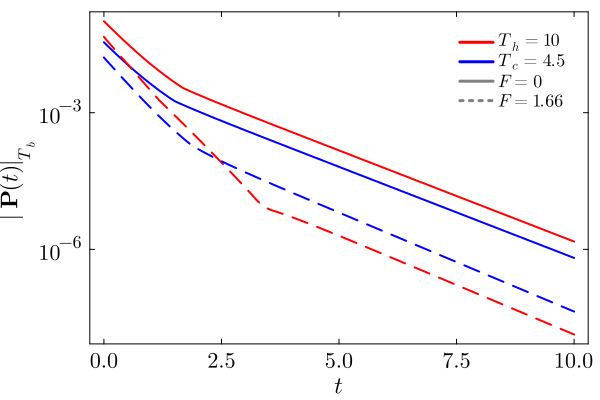

In [22]:
T_b = 3.5
concs_test = 18.5 .* [0.1,1.0]
θ = 0.6

plot_relax = plot()
ls = [:solid,:dash]
colors = [:green,:orange]

F = 0.0
M_relax = master_eqn(bs,es,T_b,concs_test,F,θ,true)
L_evec_dom = eigvecs(M_relax')[:,5]
R_evec_dom = eigvecs(M_relax)[:,5]

ss_test(T) = ss(bs,es,T,concs_test,F,θ)
hot_relax(t) = norm(ss_test(T_b) - exp(M_relax .* t)*ss_test(10.0),1)
cold_relax(t) = norm(ss_test(T_b) - exp(M_relax .* t)*ss_test(4.5),1)
println(hot_relax(0) - cold_relax(0))
println(hot_relax(50) - cold_relax(50))
plot!(plot_relax,hot_relax,0.0,10.0,yscale = :log10,lc = :red,label = L"T_h = 10",xlabel = L"t",ylabel = L"|\mathbf{P}(t)|_{T_b}")
plot!(plot_relax,cold_relax,0.0, 10.0,yscale = :log10,lc = :blue,legend = :topright,label = L"T_c = 4.5")

F = 1.66
M_relax = master_eqn(bs,es,T_b,concs_test,F,θ,true)
L_evec_dom = eigvecs(M_relax')[:,5]
R_evec_dom = eigvecs(M_relax)[:,5]

ss_test(T) = ss(bs,es,T,concs_test,F,θ)
hot_relax(t) = norm(ss_test(T_b) - exp(M_relax .* t)*ss_test(10.0),1)
cold_relax(t) = norm(ss_test(T_b) - exp(M_relax .* t)*ss_test(4.5),1)
println(hot_relax(0) - cold_relax(0))
println(hot_relax(50) - cold_relax(50))
plot!(plot_relax,hot_relax,0.0,10.0,yscale = :log10,lc = :red,ls = :dash)
plot!(plot_relax,cold_relax,0.0, 10.0,yscale = :log10,lc = :blue,ls = :dash)
plot!([NaN],[NaN], lc = :gray, label = L"F = 0")
plot!([NaN],[NaN], lc = :gray, ls = :dot, label = L"F = 1.66")


Example showing change steady state occupation probability on addition of force. Fig. 7(d) in the paper

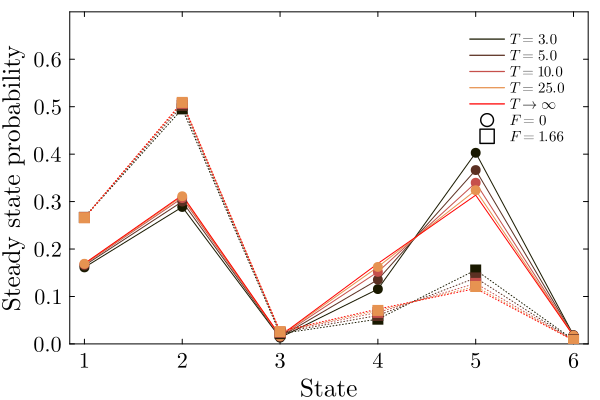

In [23]:
t_list = [3.0,5.0,10.0,25.0]
T_b = 3.0
concs_test = 18.5 .* [0.1,1.0]
F = -0.0
θ = 0.6
ss_test(T) = ss(bs,es,T,concs_test,F,θ)
ss_high_temp = nullspace(master_eqn(zeros(4),zeros(4),T_b,concs_test,F,θ))
ss_high_temp = ss_high_temp ./ sum(ss_high_temp)
ss_list = [ss_test(t) for t in t_list]

colors_list = palette(:lajolla10)[[1,3,5,7]]
plot_ss = plot(legendfontsize = 10,legend = :topright,ylims = (0.0,0.7))

for i = eachindex(t_list)
    plot!(plot_ss,ss_list[i],lc = colors_list[i],lw = 1.0,label = L"T = %$(t_list[i])")
end

plot!(plot_ss, ss_high_temp,label = L"T \to\infty",xlabel = "State", ylabel = "Steady state probability",lc = :red,lw = 1.0)
for i = eachindex(t_list)
    scatter!(plot_ss,ss_list[i],color = colors_list[i],markerstrokewidth = 0,markersize = 5.5)
end

F = 1.66
ss_test(T) = ss(bs,es,T,concs_test,F,θ)
ss_high_temp = nullspace(master_eqn(zeros(4),zeros(4),T_b,concs_test,F,θ))
ss_high_temp = ss_high_temp ./ sum(ss_high_temp)
ss_list = [ss_test(t) for t in t_list]


for i = eachindex(t_list)
    plot!(plot_ss,ss_list[i],lc = colors_list[i],lw = 1.0,ls = :dot)
end
plot!(plot_ss, ss_high_temp,lc = :red,lw = 1.0,ls = :dot)


for i = eachindex(t_list)
    scatter!(plot_ss,ss_list[i],ls = :dash,color = colors_list[i],marker = :square, markerstrokewidth = 0,markersize = 5.5)
end
scatter!([NaN,NaN], label = L"F = 0", markerstrokealpha = 0,color = :white)
scatter!([NaN,NaN], label = L"F = 1.66",marker = :square, markerstrokealpha = 0,foreground_color_legend = nothing,background_color_legend = nothing)
plot_ss


Plotting $a_2(F)$ while studying the relaxation behavior after a force quench. Fig. 8(a) in the paper

In [24]:
F_list = range(-5.0,5.0,length = 10)
a_2_s_normalized = []
T_b = 0.2
concs_test = 18.5 .* [0.1,1.0]
θ = 0.6

for F in F_list
    M_relax = master_eqn(bs,es,T_b,concs_test,F,θ)
    L_evec_dom = eigvecs(M_relax')[:,5]
    R_evec_dom = eigvecs(M_relax)[:,5]
    println(eigvals(M_relax))
    coeff(F) = dot(L_evec_dom,ss(bs,es,T_b,concs_test,F,θ))/dot(L_evec_dom,R_evec_dom)
    F_list1 = range(F - 5.0,F + 5.0,length = 200)
    a_2_list = abs.(coeff.(F_list1))
    push!(a_2_s_normalized,a_2_list./maximum(a_2_list))
end 

[-1.905985562615202, -0.2649618570030593, -0.2310869416971746, -0.02749949474235551, -0.02739636066950456, 6.476394196975244e-18]
[-1.1339695552915352, -0.2649618589648043, -0.20105513442641595, -0.027499434889791115, -0.027246576188081875, -4.643825750122922e-19]
[-0.768634344458373, -0.26496186154736107, -0.15488194255752297, -0.02749941277445411, -0.0269368128629668, 7.347316933939831e-18]
[-0.6086564196387398, -0.2649618653319442, -0.1041707068920704, -0.02749940373905069, -0.02625982172780995, 3.4891454017552555e-18]
[-0.5403025815446632, -0.2649618711139581, -0.06572785884849601, -0.02749940073648298, -0.024644101288514228, 6.171769284564161e-18]
[-0.5097690310965195, -0.264961880080624, -0.04465669403413415, -0.027499401370287852, -0.020754278048267155, 6.312872806081032e-18]
[-0.49535968871738045, -0.2649618940653714, -0.036758070090294075, -0.02749940513683681, -0.014829680865029927, -1.213113525589233e-17]
[-0.48829639344850545, -0.26496191594087903, -0.03421506539600508, -0.

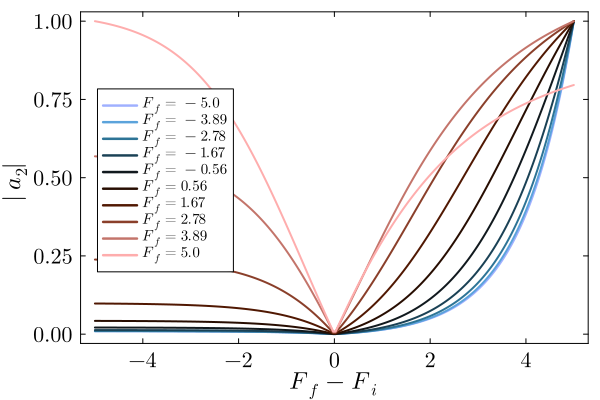

In [25]:
plot_a2 = plot(palette = :berlin10,xlabel = L"F_f - F_i",ylabel = L"|a_2|",legendfontsize = 10,background_color_legend = :white,legend = :left,foreground_color_legend = :black)
 F_list2 = range(-5.0,5.0,length = 200)
for i = eachindex(a_2_s_normalized)
    plot!(plot_a2,F_list2,a_2_s_normalized[i],label = L"F_f = %$(round(F_list[i],digits = 2))")
end
plot_a2


Showing matching behavior of $a_2$ and initial distance to steady state on changing the force. Fig. 8(c) in the paper

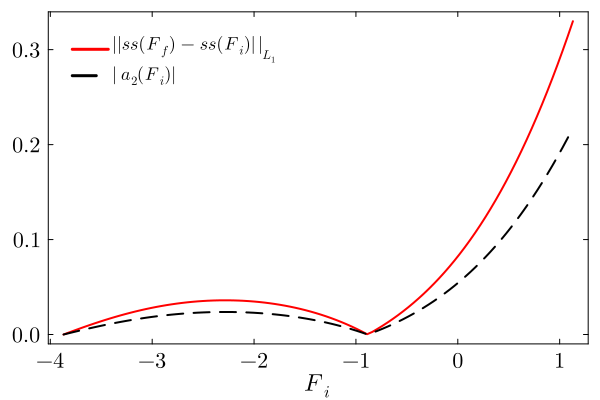

In [26]:
t_b = 0.1
F = -3.87

plot_ss_non_monoton = plot(xlabel = L"F_i")

s = 0.1 ; θ = -1.2

concs_test = s .*[0.1,1.0] 

M_relax = master_eqn(bs,es,t_b,concs_test,F,θ)
L_evec_dom = eigvecs(M_relax')[:,5]
R_evec_dom = eigvecs(M_relax)[:,5]

coeff(F) = abs(dot(L_evec_dom,ss(bs,es,t_b,concs_test,F,θ))/dot(L_evec_dom,R_evec_dom))

F_list_pos = range(F,F + 5.0,length = 100)
F_list_neg = range(F - 5.0,F ,length = 50)
a_2_list_pos = coeff.(F_list_pos)
a_2_list_neg = coeff.(F_list_neg)

initial_distance_list_pos = [norm(ss(bs,es,t_b,concs_test,F_i,θ) - ss(bs,es,t_b,concs_test,F,θ),1) for F_i in F_list_pos]
initial_distance_list_neg = [norm(ss(bs,es,t_b,concs_test,F_i,θ) - ss(bs,es,t_b,concs_test,F,θ),1) for F_i in F_list_neg]
plot!(plot_ss_non_monoton,F_list_pos,initial_distance_list_pos,label = L"||ss(F_f) - ss(F_i)||_{L_1}",lc = :red)
plot!(plot_ss_non_monoton,F_list_pos,a_2_list_pos,ls = :dash,label = L"|a_2(F_i)|",lc = :black)


In [27]:
t_b_range = range(0.1,10.0,length = 200)
scale_range = range(0.1,20.0,length = 200)
checklist = []
F = 0.0
θ = 0.3
c_list = [0.1,5.5]
push!(c_list,1.0)

for c in c_list
    checklist1 = []
    for t_b in t_b_range,s in scale_range
        concs_test = s*[0.1,1.0,c/s] 
        
        M_relax = master_eqn(bs,es,t_b,concs_test,F,θ,false)
        evals = eigvals(M_relax)
        ss_test(T) = ss(bs,es,T,concs_test,F, θ , false)
        hot_relax(t) = norm(ss_test(t_b) - exp(M_relax .* t)*ss_test(2.0))
        cold_relax(t) = norm(ss_test(t_b) - exp(M_relax .* t)*ss_test(3.5))
        
        L_evec_dom = eigvecs(M_relax')[:,5]
        R_evec_dom = eigvecs(M_relax)[:,5]
      
        coeff(t) = abs(dot(L_evec_dom,ss(bs,es,t,concs_test,F,θ,false))/dot(L_evec_dom,R_evec_dom))
        t_list = range(t_b + 0.1,t_b + 10.0,length = 100)
        a_2_list = coeff.(t_list)
        check = ifelse(issorted(a_2_list), 0.0, 1.0)
        push!(checklist1,check)
    end
    push!(checklist, checklist1)
end
    

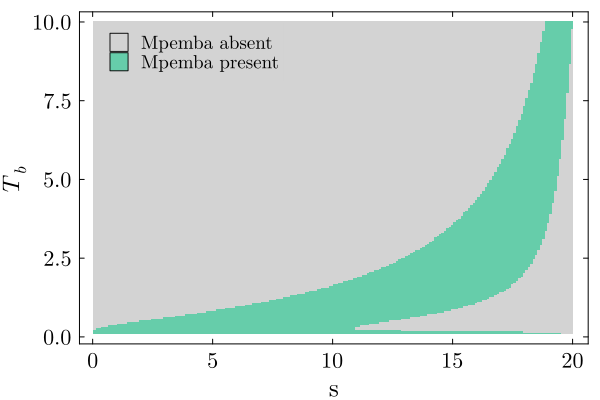

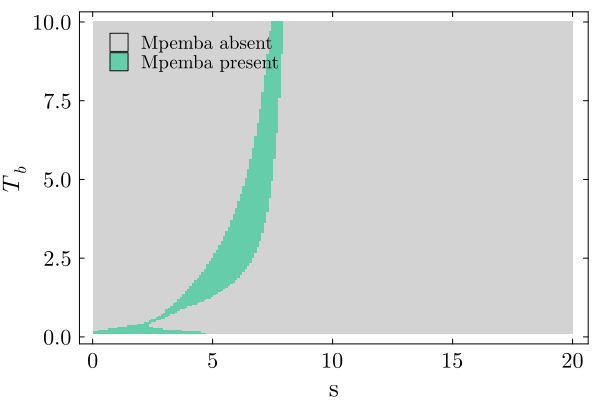

"/home/karthik/Documents/imsc-2025/notes/images/phase_diag_ts_small_c.pdf"

In [28]:

z_smallc = reshape(checklist[1], (length(scale_range), length(t_b_range)))'
z_largec = reshape(checklist[end - 1], (length(scale_range), length(t_b_range)))'
plot_smallc = heatmap(scale_range, t_b_range, z_smallc,
    xlabel="s", 
    ylabel=L"T_b",
    c = c=cgrad([ colorant"#d3d3d3ff", colorant"#66cdaaff"]),
    colorbar = :false,
    colorbar_ticks = [0.0,1.0],
    foreground_color_legend = nothing,
    background_color_legend = colorant"#d3d3d3ff")
scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#d3d3d3ff",
    label="Mpemba absent"
)

display(scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#66cdaaff",
    label="Mpemba present"
))

plot_largec = heatmap(scale_range, t_b_range, z_largec,
    xlabel="s", 
    ylabel=L"T_b",
    c = c=cgrad([ colorant"#d3d3d3ff", colorant"#66cdaaff"]),
    colorbar = :false,
    colorbar_ticks = [0.0,1.0],
    foreground_color_legend = nothing,
    background_color_legend = colorant"#d3d3d3ff")
scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#d3d3d3ff",
    label="Mpemba absent"
)

display(scatter!(
    [NaN], [NaN],
    marker=:square,
    ms=8,
    mc=colorant"#66cdaaff",
    label="Mpemba present",
    legend = :topleft,
    background_color_legend = nothing
))
